# Hipótesis (b) del inciso 4: experiencia y confianza en la IA

En este archivo vamos a analizar la hipótesis B del inciso 4:

> b) Los años de experiencia influyen en la confianza en la precisión de las herramientas de IA.

**Idea general de la resolución.** Las dos variables que necesitamos son `WorkExp` (años de experiencia, numérica) y `AIAcc` (confianza en la precisión de la IA, ordinal de 5 niveles). Como `AIAcc` es ordinal y `WorkExp` es muy asimétrica, se usan técnicas basadas en **rangos** (Spearman y Kruskal-Wallis).

**Aclaración:** la encuesta es observacional: solo permite ver si las variables se asocian, no probar causalidad.

## 0. Preparación del entorno

Instalamos dependencias. El `%` sirve para instalar en el entorno donde corre el notebook y no en el Python global.

In [8]:
%pip install pandas
%pip install seaborn
%pip install matplotlib
%pip install scipy
%pip install wget
# Después de instalar por primera vez puede hacer falta reiniciar el kernel (Kernel -> Restart)

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [9]:
from wget import download
from os import path
from itertools import combinations

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

## 1. Descarga y apertura de los datos

Descargamos la base (solo si no está ya en la carpeta).

```python
if not path.exists("schema.csv"):
    download("https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/schema.csv")
if not path.exists("results.csv"): download("https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/results.csv")
```

Abrimos los archivos. Con `low_memory=False` pandas lee la columna completa antes de decidir su tipo y evita el `DtypeWarning` de las columnas con tipos mixtos.

In [10]:
if not path.exists("schema.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/schema.csv")
if not path.exists("results.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/results.csv")

In [11]:
raw_dataset_results = pd.read_csv("results.csv", low_memory=False)
raw_dataset_schema = pd.read_csv("schema.csv")

print("results:", raw_dataset_results.shape)
print("schema:", raw_dataset_schema.shape)

results: (49191, 172)
schema: (139, 6)


## 2. Identificación de las variables en el esquema

El enunciado habla de "años de experiencia" y "confianza en la precisión de las herramientas de IA". Para saber qué columnas son, buscamos en el esquema (`schema`) por palabras clave de la pregunta. La columna `qname` del esquema es el nombre de la columna en `results`, `question` es el texto que vio la persona y `type` es el tipo de pregunta (`MC` opción múltiple, `TE` entrada de texto o número, `RO` ranking, `Matrix` matriz.

In [12]:
raw_dataset_schema[raw_dataset_schema["question"].str.contains("years|experience", case=False, na=False)][["qid", "qname", "type", "question"]]

,qid,qname,type,question
54,QID14,WorkExp,TE,"How many years of professional work experience do you have? Please round to the nearest whole number, excluding any decimal points. If your answer is '0', please leave blank."
59,QID13,YearsCode,TE,"Including any education, how many years have you been coding in total? Please round to the nearest whole number, excluding any decimal points."
95,QID39,SOTags,Matrix,"Which rising technology of the added as <b>new tag or tag subject area on Stack Overflow</b> in the last three years <strong>have you used</strong> regularly in the past year, and which do you <strong>want to work with</strong> over the next year? Please check all that apply.<br>\n"
96,QID62,SOTagsHaveEntry,TE,"Was the new tag on Stack Overflow (i.e. added in the last 2 - 3 years) you use not listed above? List below, separated by a comma and a space for each, what <strong>you used in the past year</strong>."
97,QID63,SOTagsWant Entry,TE,"Was the new tag on Stack Overflow (i.e. added in the last 2 - 3 years) you want to use not listed above? List below, separated by a comma and a space for each, what <strong>you want to use next year</strong>."
120,QID82,AITool,Matrix,Which parts of your development workflow are you currently integrating into AI or using AI tools to accomplish or plan to use AI to accomplish over the next 3 - 5 years? Please select one for each scenario.
138,QID93,AIOpen,TE,"Looking ahead 3–5 years, what skills do you believe will remain valuable for developers even as AI tools become more capable? Please describe."


In [13]:
raw_dataset_schema[raw_dataset_schema["question"].str.contains("trust the accuracy|accuracy of the output", case=False, na=False)][["qid", "qname", "type", "question"]]

,qid,qname,type,question
118,QID80,AIAcc,MC,How much do you trust the accuracy of the output from AI tools as part of your development workflow?


Con las búsquedas identificamos `WorkExp` y `AIAcc`. Confirmamos la fila exacta de cada una (el `qid`, el tipo y el texto de la pregunta).

**Resumen de las variables**

| Variable | Qué mide | Tipo de pregunta | Tipo estadístico |
| --- | --- | --- | --- |
| `WorkExp` | Años de experiencia profesional | `TE` (se escribe un número) | Numérica discreta |
| `AIAcc` | "¿Cuánto confiás en la precisión de lo que producen las herramientas de IA en tu flujo de trabajo?" | `MC` (una opción) | **Ordinal** de 5 niveles |

Esta es la parte que más importa: `AIAcc` tiene un orden, pero no sabemos que la distancia entre categorías sea la misma. Por eso no se usan técnicas que supongan normalidad o variables de intervalo: se usan técnicas basadas en **rangos** (Spearman y Kruskal-Wallis).

## 3. Filtrado y limpieza específica para esta hipótesis

El dataset es muy grande y solo nos interesan estas dos columnas. Las guardamos en una variable nueva para **no modificar los datos crudos**. Incluimos también `Age` (la usamos más adelante en un chequeo de robustez.

Se ve que hay muchos nulos: `WorkExp` tiene alrededor de 12,8% y `AIAcc` alrededor de 32%. Un nulo en `AIAcc` puede significar que la persona no respondió, o que la pregunta no le apareció. El esquema no documenta esas condiciones, así que lo dejamos como **hipótesis** y más adelante chequeamos si los nulos parecen concentrarse en cierto nivel de experiencia (sección 4).

In [14]:
df_hipotesis_b = raw_dataset_results[["WorkExp", "AIAcc", "Age"]].copy()
df_hipotesis_b.head()

,WorkExp,AIAcc,Age
0,8.0,Neither trust nor distrust,25-34 years old
1,2.0,Neither trust nor distrust,25-34 years old
2,10.0,Somewhat trust,35-44 years old
3,4.0,Somewhat trust,35-44 years old
4,21.0,Neither trust nor distrust,35-44 years old


In [15]:
UMBRAL_EXP = 99

print("WorkExp pasados a nulo:", (df_hipotesis_b["WorkExp"] >= UMBRAL_EXP).sum())
df_hipotesis_b["WorkExp"] = df_hipotesis_b["WorkExp"].mask(df_hipotesis_b["WorkExp"] >= UMBRAL_EXP)

WorkExp pasados a nulo: 39


In [16]:
ORDEN = ["Highly distrust", "Somewhat distrust", "Neither trust nor distrust",
         "Somewhat trust", "Highly trust"]
mapa = {nivel: i + 1 for i, nivel in enumerate(ORDEN)}

df_hipotesis_b["AIAcc_ord"] = pd.Categorical(df_hipotesis_b["AIAcc"], categories=ORDEN, ordered=True)
df_hipotesis_b["AIAcc_num"] = df_hipotesis_b["AIAcc"].map(mapa)

sin_mapear = df_hipotesis_b["AIAcc"].notna() & df_hipotesis_b["AIAcc_num"].isna()
print("Respuestas con un texto no reconocido:", sin_mapear.sum(), "(debe ser 0)")

Respuestas con un texto no reconocido: 0 (debe ser 0)


In [17]:
df_limpio_b = df_hipotesis_b.dropna(subset=["WorkExp", "AIAcc_num"]).copy()
n = len(df_limpio_b)

pd.Series({
    "Filas totales": len(df_hipotesis_b),
    "Con AIAcc respondida": df_hipotesis_b["AIAcc"].notna().sum(),
    "Con WorkExp válida": df_hipotesis_b["WorkExp"].notna().sum(),
    "Con ambas (n del análisis)": n,
})

Filas totales                 49191
Con AIAcc respondida          33297
Con WorkExp válida            42854
Con ambas (n del análisis)    30765
dtype: int64

## 4. Exploración de las variables

Antes de aplicar cualquier prueba **miramos los datos**. Distribución de `AIAcc`, de `WorkExp`, tabla y boxplot por nivel de confianza, scatter de experiencia vs confianza, y skew de `WorkExp`.

In [18]:
dist = df_limpio_b["AIAcc_ord"].value_counts().reindex(ORDEN)
pd.DataFrame({"n": dist, "%": (dist / n * 100).round(1)})

,n,%
AIAcc_ord,,
Highly distrust,5991,19.5
Somewhat distrust,8036,26.1
Neither trust nor distrust,6674,21.7
Somewhat trust,9141,29.7
Highly trust,923,3.0


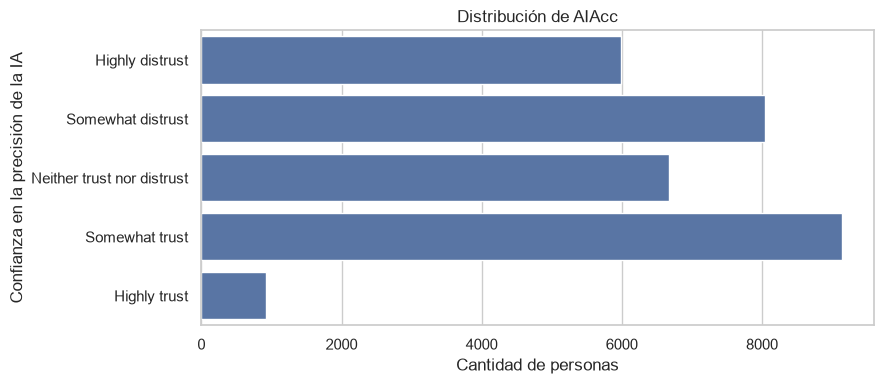

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.countplot(data=df_limpio_b, y="AIAcc_ord", order=ORDEN, ax=ax)
ax.set_xlabel("Cantidad de personas")
ax.set_ylabel("Confianza en la precisión de la IA")
ax.set_title("Distribución de AIAcc")
plt.tight_layout()
plt.show()

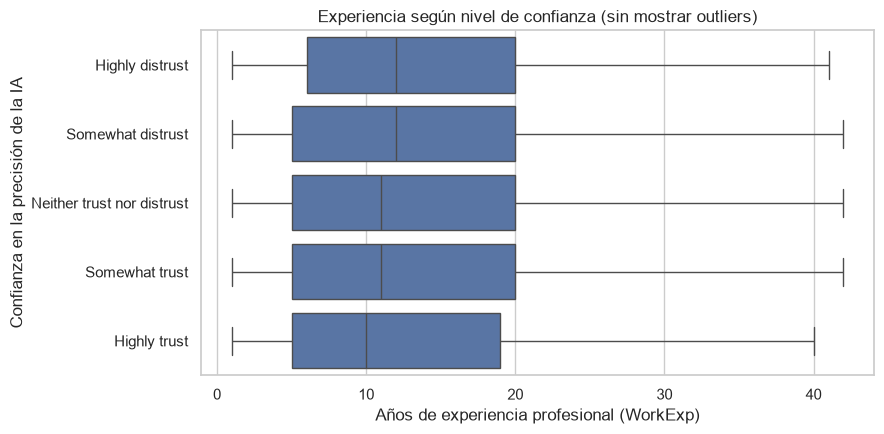

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df_limpio_b, y="AIAcc_ord", x="WorkExp", ax=ax, showfliers=False)
ax.set_xlabel("Años de experiencia profesional (WorkExp)")
ax.set_ylabel("Confianza en la precisión de la IA")
ax.set_title("Experiencia según nivel de confianza (sin mostrar outliers)")
plt.tight_layout()
plt.show()

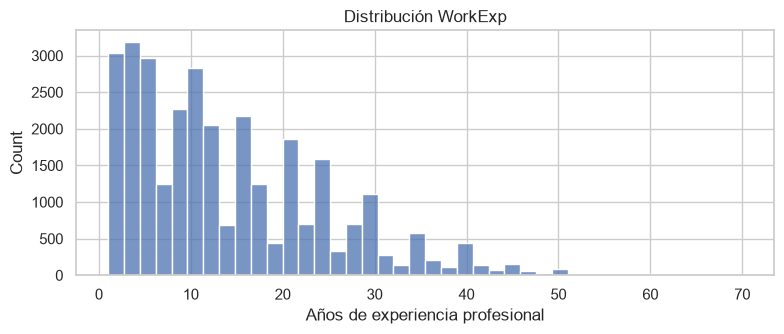

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(df_limpio_b["WorkExp"], bins=40, ax=ax)
ax.set_xlabel("Años de experiencia profesional")
ax.set_title("Distribución WorkExp")
plt.tight_layout()
plt.show()

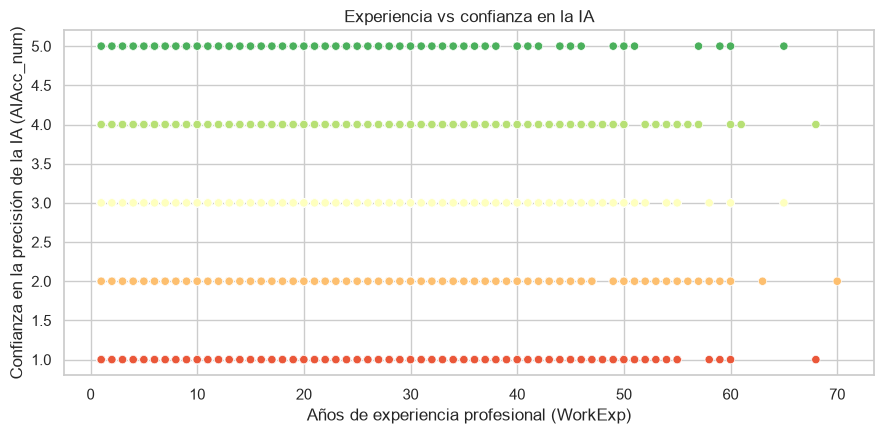

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.scatterplot(data=df_limpio_b, x="WorkExp", y="AIAcc_num", hue="AIAcc_ord", palette="RdYlGn", legend=False, ax=ax)
ax.set_xlabel("Años de experiencia profesional (WorkExp)")
ax.set_ylabel("Confianza en la precisión de la IA (AIAcc_num)")
ax.set_title("Experiencia vs confianza en la IA")
plt.tight_layout()
plt.show()

Una asimetría positiva (skew mayor a 0) con media mayor que la mediana indica una cola larga hacia valores altos: muchas personas con poca experiencia y pocas con muchísima. **Esto descarta los métodos que suponen normalidad** (Pearson).

## 5. Elección de la técnica y verificación de supuestos

| Técnica candidata | ¿Sirve? | Por qué |
| --- | --- | --- |
| Correlación de **Pearson** | No | Exige variables de intervalo y relación lineal. `AIAcc` es ordinal y `WorkExp` muy asimétrica |
| Correlación de **Spearman** | **Sí (prueba principal)** | Usa rangos: sirve para ordinales y no exige normalidad. Mide asociación monótona |
| **Kruskal-Wallis** | **Sí (complemento)** | Compara la experiencia entre los grupos sin suponer normalidad. No usa el orden de los grupos |

**Supuestos de Spearman y cómo se verifican**

1. **Observaciones independientes:** cada fila es una persona distinta.
2. **Variables al menos ordinales:** `AIAcc` es ordinal, `WorkExp` es numérica. Cumple.
3. **Relación monótona:** no hace falta que sea lineal, pero no debería cambiar de dirección. Se revisa visualmente.

## 6. Prueba principal: correlación de Spearman

**Hipótesis estadísticas.** Sea ρ (rho) la correlación de rangos de Spearman entre `WorkExp` y `AIAcc` en la población que responde la encuesta.

- **H0:** ρ = 0. No hay asociación monótona entre experiencia y confianza en la IA.
- **H1:** ρ ≠ 0. Hay asociación monótona (en cualquier sentido).

Se plantea **bilateral** porque el enunciado dice que la experiencia "influye" sin decir en qué dirección. **Nivel de significación: α = 0,05.**

In [23]:
ALFA = 0.05

rho, p_rho = stats.spearmanr(df_limpio_b["WorkExp"], df_limpio_b["AIAcc_num"])

print(f"n = {n}")
print(f"rho de Spearman = {rho:.4f}")
print(f"p-valor = {p_rho:.3g}")

n = 30765
rho de Spearman = -0.0339
p-valor = 2.64e-09


**Cómo leer cada número**

- **ρ (rho):** va de -1 a +1. Positivo: a más experiencia, más confianza. Negativo: a más experiencia, menos confianza. Cercano a 0: sin asociación monótona.
- **p-valor:** probabilidad de obtener una correlación tan extrema como la observada **si H0 fuera cierta**. Si es menor que α se rechaza H0. **No** es la probabilidad de que H0 sea cierta ni mide qué tan grande es el efecto.

**Magnitud** (convención orientativa), según el valor absoluto de ρ: menor a 0,1 despreciable; de 0,1 a 0,3 pequeña; de 0,3 a 0,5 moderada; mayor a 0,5 grande.

In [24]:
def magnitud_rho(r):
    r = abs(r)
    if r < 0.1:
        return "despreciable"
    if r < 0.3:
        return "pequeña"
        
    if r < 0.5:
        return "moderada"
    return "grande"

print("Significativa al", ALFA, ":", p_rho < ALFA)
print("Dirección:", "positiva" if rho > 0 else "negativa")
print("Magnitud:", magnitud_rho(rho))

Significativa al 0.05 : True
Dirección: negativa
Magnitud: despreciable


## 7. Prueba complementaria: Kruskal-Wallis

Spearman usa el orden de los niveles. Kruskal-Wallis hace una pregunta distinta: **¿la experiencia es distinta en al menos uno de los 5 grupos?**, sin usar el orden. Si las dos pruebas coinciden, la conclusión es más sólida.

- **H0:** la distribución de `WorkExp` es la misma en los 5 niveles de confianza.
- **H1:** al menos un nivel difiere de los otros.

Ordena a todas las personas por experiencia (rangos) y compara el rango promedio de cada grupo. El estadístico **H** crece cuanto más se separan esos promedios.

In [25]:
grupos = [g["WorkExp"].values for _, g in df_limpio_b.groupby("AIAcc_ord", observed=True)]
H, p_kw = stats.kruskal(*grupos)

print(f"H = {H:.2f}  (grados de libertad = {len(grupos) - 1})")
print(f"p-valor = {p_kw:.3g}")

H = 38.68  (grados de libertad = 4)
p-valor = 8.1e-08


Un p-valor chico en Kruskal-Wallis solo dice que **hay alguna diferencia**, no entre qué grupos. Para saberlo se comparan los grupos de a pares con **Mann-Whitney**.

In [26]:
filas = []
for a, b in combinations(ORDEN, 2):
    xa = df_limpio_b.loc[df_limpio_b["AIAcc"] == a, "WorkExp"]
    xb = df_limpio_b.loc[df_limpio_b["AIAcc"] == b, "WorkExp"]
    U, p = stats.mannwhitneyu(xa, xb, alternative="two-sided")
    filas.append({
        "grupo A": a, "grupo B": b,
        "mediana A": xa.median(), "mediana B": xb.median(),
        "P(A > B)": U / (len(xa) * len(xb)),
        "p": p,
    })

posthoc = pd.DataFrame(filas)
posthoc.round(4)

,grupo A,grupo B,mediana A,mediana B,P(A > B),p
0,Highly distrust,Somewhat distrust,12.0,12.0,0.5106,0.0321
1,Highly distrust,Neither trust nor distrust,12.0,11.0,0.5143,0.0054
2,Highly distrust,Somewhat trust,12.0,11.0,0.5248,0.0000
3,Highly distrust,Highly trust,12.0,10.0,0.5455,0.0000
4,Somewhat distrust,Neither trust nor distrust,12.0,11.0,0.5036,0.4467
5,Somewhat distrust,Somewhat trust,12.0,11.0,0.5141,0.0014
6,Somewhat distrust,Highly trust,12.0,10.0,0.5345,0.0006
7,Neither trust nor distrust,Somewhat trust,11.0,11.0,0.5104,0.0258
8,Neither trust nor distrust,Highly trust,11.0,10.0,0.5310,0.0022
9,Somewhat trust,Highly trust,11.0,10.0,0.5211,0.0341


## 8. Chequeo de robustez

### 8.1 Otra medida de asociación: tau de Kendall

Kendall es otra correlación de rangos, más robusta cuando hay muchos empates (como acá). Si da una conclusión coherente con Spearman, el resultado no depende de la técnica elegida.

In [27]:
tau, p_tau = stats.kendalltau(df_limpio_b["WorkExp"], df_limpio_b["AIAcc_num"])
print(f"tau-b de Kendall = {tau:.4f} | p-valor = {p_tau:.3g}")
print(f"rho de Spearman  = {rho:.4f}")

tau-b de Kendall = -0.0256 | p-valor = 2.76e-09
rho de Spearman  = -0.0339


## 9. Conclusión

La celda siguiente toma los resultados calculados y arma un **borrador** de la conclusión, para que el texto no pueda contradecir a los números. Hay que revisarlo y reescribirlo con palabras propias antes de pasarlo al informe.

In [28]:
decision = "se rechaza H0" if p_rho < ALFA else "no se rechaza H0"
sentido = "positiva (a más experiencia, más confianza)" if rho > 0 else "negativa (a más experiencia, menos confianza)"

print("RESUMEN DE LA HIPÓTESIS (b)")
print("-" * 70)
print(f"n = {n}")
print(f"Spearman: rho = {rho:.3f}, p = {p_rho:.3g}")
print(f"  -> Con alfa = {ALFA}, {decision}.")
print(f"  -> Asociación {sentido}, de magnitud {magnitud_rho(rho)}.")
print(f"Kruskal-Wallis: H = {H:.1f}, p = {p_kw:.3g}")
print(f"Kendall: tau-b = {tau:.3f}, p = {p_tau:.3g}")
print("-" * 70)
print()
print("BORRADOR DE REDACCIÓN")
print(
    f"Con n = {n} personas que respondieron ambas preguntas, la correlación de Spearman entre años de "
    f"experiencia y confianza en la precisión de la IA fue rho = {rho:.3f}, "
    f"p = {p_rho:.3g}. Con alfa = {ALFA}, {decision}. La asociación es {sentido} y de magnitud "
    f"{magnitud_rho(rho)}. La prueba complementaria de Kruskal-Wallis {'coincide' if p_kw < ALFA else 'no coincide'} con el resultado (H = {H:.1f}, p = {p_kw:.3g}). "
    f"Kendall {'confirma' if (np.sign(tau) == np.sign(rho)) and ((p_tau < ALFA) == (p_rho < ALFA)) else 'no confirma'} el resultado."
)

RESUMEN DE LA HIPÓTESIS (b)
----------------------------------------------------------------------
n = 30765
Spearman: rho = -0.034, p = 2.64e-09
  -> Con alfa = 0.05, se rechaza H0.
  -> Asociación negativa (a más experiencia, menos confianza), de magnitud despreciable.
Kruskal-Wallis: H = 38.7, p = 8.1e-08
Kendall: tau-b = -0.026, p = 2.76e-09
----------------------------------------------------------------------

BORRADOR DE REDACCIÓN
Con n = 30765 personas que respondieron ambas preguntas, la correlación de Spearman entre años de experiencia y confianza en la precisión de la IA fue rho = -0.034, p = 2.64e-09. Con alfa = 0.05, se rechaza H0. La asociación es negativa (a más experiencia, menos confianza) y de magnitud despreciable. La prueba complementaria de Kruskal-Wallis coincide con el resultado (H = 38.7, p = 8.1e-08). Kendall confirma el resultado.
